---
title: "Exact Differentials and Thermodynamic Calculus"
short_title: "T-M3 Thermodynamic Calculus"
numbering:
  heading_2: true
  equation: true
---

# Exact Differentials and Thermodynamic Calculus

:::{tip} Where this sits in the plan
Math for the **first law**, **engines** and **free energy** (thermo topics 2, 4 and 5). Mechanics M3 covers partial derivatives and Lagrange multipliers, and M7 covers the Legendre transform; this notebook puts them to thermodynamic use.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Partial derivatives and the gradient | 14 | 4 | 9 | 3 |
| Exact differentials and line integrals | 16 | 4, 6 | – | 3 |
| Legendre transform | – | 4 | – | – |
| Lagrange multipliers | 14 | 4 | – | 22 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [First Law, Heat, Work and Heat Capacity](../thermo/02-first-law-heat-capacity.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Which Variable Is Held Fixed?**

   For an ideal gas, $PV = NkT$:

   (a) Find $(\partial P/\partial T)_V$, $(\partial V/\partial T)_P$ and $(\partial P/\partial V)_T$.

   (b) Check that $(\partial P/\partial T)_V(\partial T/\partial V)_P(\partial V/\partial P)_T = -1$.

2. **Exact and Inexact Differentials**

   (a) Is $2xy\,dx + (x^2 + 3y^2)\,dy$ exact? If so, find $f$.

   (b) For an ideal gas, $\delta Q = C_V\,dT + (NkT/V)\,dV$. Show that this is inexact, that $\delta Q/T$ is exact, and find the resulting function.

3. **Maxwell Relations**

   (a) Derive the Maxwell relations that follow from $dF = -S\,dT - P\,dV$ and from $dG = -S\,dT + V\,dP$.

   (b) Evaluate $(\partial S/\partial V)_T$ for an ideal gas.

4. **Legendre Transforms: Changing the Natural Variables**

   Give the natural variables of $U$, $H$, $F$ and $G$, and write $dH$.

5. **Lagrange Multipliers and the Most Probable Distribution**

   (a) Maximize $-\sum p_i\ln p_i$ subject only to $\sum p_i = 1$. What distribution results?

   (b) Adding a fixed average energy gives $p_i \propto e^{-\beta E_i}$. Write the partition function for levels $0$, $\epsilon$ and $2\epsilon$.

:::{dropdown} Answers
1. (a) $Nk/V$, $Nk/P$ and $-NkT/V^2$.

   (b) $\dfrac{Nk}{V}\cdot\dfrac{P}{Nk}\cdot\left(-\dfrac{V^2}{NkT}\right) = -\dfrac{PV}{NkT} = -1$.

2. (a) Yes: both mixed partials equal $2x$. $f = x^2y + y^3$.

   (b) $\partial_V C_V = 0 \ne \partial_T(NkT/V) = Nk/V$, so $\delta Q$ is inexact. $\delta Q/T = (C_V/T)\,dT + (Nk/V)\,dV$ passes the test, and integrates to $S = C_V\ln T + Nk\ln V + \text{const}$.

3. (a) $(\partial S/\partial V)_T = (\partial P/\partial T)_V$ and $-(\partial S/\partial P)_T = (\partial V/\partial T)_P$.

   (b) $Nk/V$.

4. $U(S, V)$, $H(S, P)$, $F(T, V)$ and $G(T, P)$. $dH = T\,dS + V\,dP$.

5. (a) The uniform distribution.

   (b) $Z = 1 + e^{-\beta\epsilon} + e^{-2\beta\epsilon}$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Which Variable Is Held Fixed?

In mechanics a partial derivative's held variables are usually obvious. In thermodynamics they are not: the state of a simple gas is fixed by any two of $P, V, T, S, U, \ldots$, so "the derivative of $U$ with respect to $T$" means different things depending on whether $V$ or $P$ is held constant. The notation always says:

$$
\left(\frac{\partial U}{\partial T}\right)_V\quad\ne\quad\left(\frac{\partial U}{\partial T}\right)_P\quad\text{in general.}
$$

The first is the heat capacity at constant volume, $C_V$. The second is not even a heat capacity; $C_P$ is $(\partial H/\partial T)_P$ (thermo topic 2).

### Three identities

For any three variables $x, y, z$ related by one equation (so any two determine the third):

$$
\left(\frac{\partial x}{\partial y}\right)_z = \frac{1}{(\partial y/\partial x)_z} ,
$$ (eq-reciprocal)

$$
\left(\frac{\partial x}{\partial y}\right)_z\left(\frac{\partial y}{\partial z}\right)_x\left(\frac{\partial z}{\partial x}\right)_y = -1 ,
$$ (eq-triple-product)

and, if $w$ is any function of the same state, the chain rule with a change of held variable:

$$
\left(\frac{\partial w}{\partial x}\right)_z = \left(\frac{\partial w}{\partial x}\right)_y + \left(\frac{\partial w}{\partial y}\right)_x\left(\frac{\partial y}{\partial x}\right)_z .
$$ (eq-change-held)

The $-1$ in {eq}`eq-triple-product` surprises everyone once. It comes from setting $dz = 0$ in $dz = (\partial z/\partial x)_ydx + (\partial z/\partial y)_xdy$ and solving for $dx/dy$.

In [2]:
# Check the triple product rule on the ideal gas PV = NkT
P, V, T, N, k = sp.symbols("P V T N k", positive=True)
P_of = N * k * T / V          # P(V, T)
V_of = N * k * T / P          # V(P, T)
T_of = P * V / (N * k)        # T(P, V)
triple = sp.diff(P_of, V) * sp.diff(V_of, T) * sp.diff(T_of, P)
triple = sp.simplify(triple.subs(T, P * V / (N * k)))
display(Math(r"\left(\frac{\partial P}{\partial V}\right)_T\left(\frac{\partial V}{\partial T}\right)_P\left(\frac{\partial T}{\partial P}\right)_V = " + sp.latex(triple)))

<IPython.core.display.Math object>

## Exact and Inexact Differentials

An expression $dF = M(x,y)\,dx + N(x,y)\,dy$ is **exact** if it is the differential of some function $F(x, y)$, so that $M = \partial F/\partial x$ and $N = \partial F/\partial y$. Since mixed partials are equal, a necessary (and, on a simply connected region, sufficient) test is

$$
\frac{\partial M}{\partial y} = \frac{\partial N}{\partial x} .
$$ (eq-exactness)

If $dF$ is exact, $\int dF$ along a path depends only on the endpoints, and $\oint dF = 0$ around any closed loop. These are the properties of a **state function**.

**Heat and work are not exact.** For a quasistatic ideal-gas process, $W_{\text{by gas}} = \int P\,dV$, and $P\,dV = (NkT/V)\,dV + 0\,dT$ fails the test: $\partial(NkT/V)/\partial T = Nk/V \ne 0 = \partial(0)/\partial V$. The work depends on the path, which is the whole reason an engine can run in a cycle and produce net work. Thermo books write $\delta Q$ and $\delta W$ (or $Q$ and $W$ with no $d$) to flag this.

:::{prf:theorem} An integrating factor turns heat into entropy
:label: thm-integrating-factor

For a quasistatic process in an ideal gas, $\delta Q = C_V\,dT + (NkT/V)\,dV$ is inexact, but $\delta Q/T = (C_V/T)\,dT + (Nk/V)\,dV$ is exact. Its integral is the entropy change:

$$
\Delta S = C_V\ln\frac{T_2}{T_1} + Nk\ln\frac{V_2}{V_1} .
$$ (eq-ideal-gas-entropy-change)

$1/T$ is an **integrating factor**: a multiplier that makes an inexact differential exact. The second law says this works for every system, not only ideal gases.
:::

In [3]:
Cv = sp.symbols("C_V", positive=True)
M_Q, N_Q = Cv, N * k * T / V          # dQ = M dT + N dV
M_S, N_S = Cv / T, N * k / V          # dQ/T
test = lambda M_, N_: sp.simplify(sp.diff(M_, V) - sp.diff(N_, T))
display(Math(r"\delta Q:\ \ \partial_V M - \partial_T N = " + sp.latex(test(M_Q, N_Q))))
display(Math(r"\delta Q/T:\ \ \partial_V M - \partial_T N = " + sp.latex(test(M_S, N_S))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

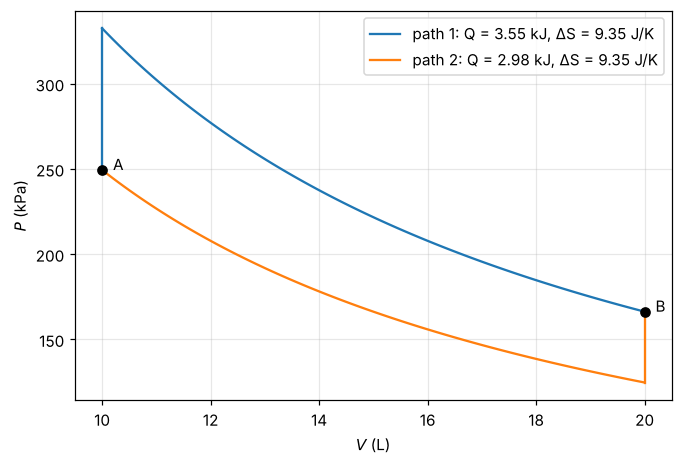

In [4]:
#| label: fig-path-dependence
#| caption: "Two quasistatic paths from state A to state B of one mole of ideal gas (monatomic). The heat absorbed differs between paths (3.55 vs 2.98 kJ here), but ΔS = ∫δQ/T is the same 9.35 J/K on both, because δQ/T is exact."
Nk = 8.314; CV = 1.5 * Nk
VA, TA, VB, TB = 0.01, 300.0, 0.02, 400.0
PA, PB = Nk * TA / VA, Nk * TB / VB
def heat_and_entropy(path):
    Q = S = 0.0
    for (V1, T1), (V2, T2) in zip(path[:-1], path[1:]):
        if V1 == V2:           # constant volume
            Q += CV * (T2 - T1); S += CV * np.log(T2 / T1)
        else:                  # constant temperature
            Q += Nk * T1 * np.log(V2 / V1); S += Nk * np.log(V2 / V1)
    return Q, S
p1 = [(VA, TA), (VA, TB), (VB, TB)]    # heat at fixed V, then expand at T_B
p2 = [(VA, TA), (VB, TA), (VB, TB)]    # expand at T_A, then heat at fixed V
fig, ax = plt.subplots()
for path, col, name in [(p1, "tab:blue", "path 1"), (p2, "tab:orange", "path 2")]:
    for (V1, T1), (V2, T2) in zip(path[:-1], path[1:]):
        if V1 == V2:
            ax.plot([V1 * 1e3] * 2, [Nk * T1 / V1 / 1e3, Nk * T2 / V2 / 1e3], color=col)
        else:
            vv = np.linspace(V1, V2, 100); ax.plot(vv * 1e3, Nk * T1 / vv / 1e3, color=col)
    Q, S = heat_and_entropy(path)
    ax.plot([], [], color=col, label=f"{name}: Q = {Q/1e3:.2f} kJ, ΔS = {S:.2f} J/K")
ax.plot([VA * 1e3, VB * 1e3], [PA / 1e3, PB / 1e3], "ko"); ax.text(VA * 1e3 + 0.2, PA / 1e3, "A"); ax.text(VB * 1e3 + 0.2, PB / 1e3, "B")
ax.set_xlabel("$V$ (L)"); ax.set_ylabel("$P$ (kPa)"); ax.legend(); plt.show()

## Maxwell Relations

The thermodynamic identity (thermo topic 3) is $dU = T\,dS - P\,dV$. Read as an exact differential of $U(S, V)$, it says

$$
T = \left(\frac{\partial U}{\partial S}\right)_V,\qquad -P = \left(\frac{\partial U}{\partial V}\right)_S .
$$

Equality of mixed partials of $U$ then gives a relation nobody would guess:

$$
\left(\frac{\partial T}{\partial V}\right)_S = -\left(\frac{\partial P}{\partial S}\right)_V .
$$ (eq-maxwell-u)

Each thermodynamic potential gives one such **Maxwell relation**:

| Potential | Differential | Maxwell relation |
|---|---|---|
| $U(S, V)$ | $T\,dS - P\,dV$ | $(\partial T/\partial V)_S = -(\partial P/\partial S)_V$ |
| $H = U + PV$ | $T\,dS + V\,dP$ | $(\partial T/\partial P)_S = (\partial V/\partial S)_P$ |
| $F = U - TS$ | $-S\,dT - P\,dV$ | $(\partial S/\partial V)_T = (\partial P/\partial T)_V$ |
| $G = U - TS + PV$ | $-S\,dT + V\,dP$ | $(\partial S/\partial P)_T = -(\partial V/\partial T)_P$ |

The last two are the useful ones: they trade a derivative of entropy, which no instrument measures, for a derivative of $P$, $V$ and $T$, which the equation of state supplies.

::::{prf:example} How entropy depends on volume
:label: ex-maxwell-vdw

Find $(\partial S/\partial V)_T$ for a van der Waals gas, $\left(P + aN^2/V^2\right)(V - Nb) = NkT$.

:::{dropdown} Solution
By the $F$ relation, $(\partial S/\partial V)_T = (\partial P/\partial T)_V$. Solving for $P = NkT/(V - Nb) - aN^2/V^2$,

$$
\left(\frac{\partial S}{\partial V}\right)_T = \frac{Nk}{V - Nb} .
$$

So isothermal expansion from $V_1$ to $V_2$ raises the entropy by $Nk\ln[(V_2 - Nb)/(V_1 - Nb)]$. The attraction $a$ drops out; only the excluded volume $b$ matters.
:::
::::

## Legendre Transforms: Changing the Natural Variables

The potentials in the table are Legendre transforms of $U$ (mechanics M7 has the general idea). $U(S, V)$ is natural when $S$ and $V$ are controlled; in the lab you usually control $T$ instead. Subtracting $TS$ swaps the roles:

$$
dF = d(U - TS) = T\,dS - P\,dV - T\,dS - S\,dT = -S\,dT - P\,dV ,
$$

so $F$ is naturally a function of $T$ and $V$. The rule: **to trade a variable for its conjugate, subtract the product.** $(S, T)$ and $(V, -P)$ are the conjugate pairs; adding chemical potential gives a third, $(N, \mu)$.

Geometrically, $F(T)$ at fixed $V$ is the intercept of the tangent line to $U(S)$ with slope $T$, which is why the transform loses no information as long as $U$ is convex in $S$.

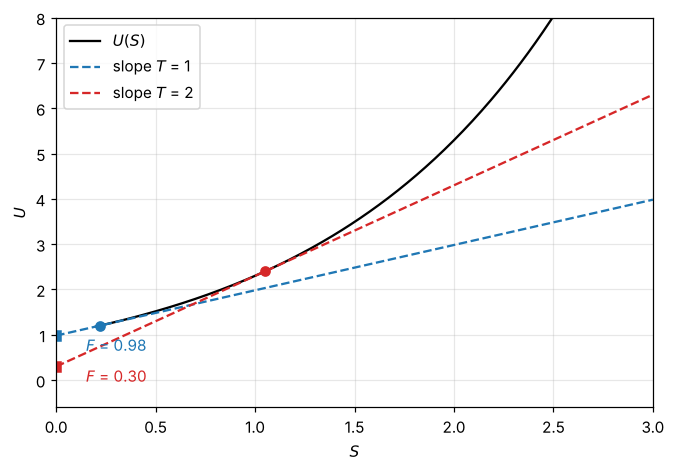

In [5]:
#| label: fig-legendre-thermo
#| caption: "The Legendre transform F = U − TS read off a graph of U(S) at fixed V. The tangent line of slope T meets the U axis at F. Each slope picks out one tangent, so F(T) holds the same information as U(S)."
S_ = np.linspace(0.2, 3, 300)
U_ = np.exp(S_ / 1.2)                        # a convex U(S), arbitrary units
Ts = [1.0, 2.0]
fig, ax = plt.subplots()
ax.plot(S_, U_, color="k", label="$U(S)$")
for Tt, col in zip(Ts, ["tab:blue", "tab:red"]):
    S0 = 1.2 * np.log(1.2 * Tt); U0 = np.exp(S0 / 1.2); F0 = U0 - Tt * S0
    ss = np.linspace(0, 3, 10); ax.plot(ss, F0 + Tt * ss, "--", color=col, label=f"slope $T$ = {Tt:g}")
    ax.plot([S0], [U0], "o", color=col); ax.plot([0], [F0], "s", color=col)
    ax.annotate(f"$F$ = {F0:.2f}", (0, F0), (0.15, F0 - 0.35), color=col)
ax.set_xlim(0, 3); ax.set_ylim(-0.6, 8); ax.set_xlabel("$S$"); ax.set_ylabel("$U$"); ax.legend(loc="upper left"); plt.show()

## Lagrange Multipliers and the Most Probable Distribution

To maximize $f(x_1, \ldots, x_n)$ subject to constraints $g_j(x) = c_j$, set

$$
\nabla f = \sum_j\lambda_j\nabla g_j
$$ (eq-lagrange-multipliers)

and solve together with the constraints (mechanics M3). In statistical mechanics the multipliers turn out to be physical quantities.

::::{prf:example} The Boltzmann distribution from maximum entropy
:label: ex-max-entropy

Probabilities $p_i$ over states of energy $E_i$ must satisfy $\sum p_i = 1$ and $\sum p_iE_i = \bar E$. Maximize the Gibbs entropy $S/k = -\sum p_i\ln p_i$.

:::{dropdown} Solution
With multipliers $\alpha$ and $\beta$, set $\partial/\partial p_i$ of $-\sum p\ln p - \alpha\sum p - \beta\sum pE$ to zero:

$$
-\ln p_i - 1 - \alpha - \beta E_i = 0\quad\Rightarrow\quad p_i = \frac{e^{-\beta E_i}}{Z},\qquad Z = \sum_ie^{-\beta E_i} .
$$

The normalization multiplier became $Z$, and comparing with thermodynamics (thermo topic 6) shows $\beta = 1/kT$: **temperature is the Lagrange multiplier for the energy constraint.**
:::
::::

In [6]:
# Numerical check: maximize the entropy of 5 levels with fixed mean energy, then compare with exp(-beta E)
from scipy.optimize import minimize
E = np.arange(5.0); Ebar = 1.2
cons = [{"type": "eq", "fun": lambda p: p.sum() - 1}, {"type": "eq", "fun": lambda p: p @ E - Ebar}]
res = minimize(lambda p: np.sum(p * np.log(p)), np.full(5, 0.2), constraints=cons, bounds=[(1e-9, 1)] * 5)
p = res.x
beta = brentq(lambda b_: (E * np.exp(-b_ * E)).sum() / np.exp(-b_ * E).sum() - Ebar, -5, 5)
boltz = np.exp(-beta * E) / np.exp(-beta * E).sum()
display(Math(r"p_{\text{max }S} = " + sp.latex(sp.Matrix(np.round(p, 4)).T)))
display(Math(r"e^{-\beta E_i}/Z = " + sp.latex(sp.Matrix(np.round(boltz, 4)).T) + rf",\quad \beta = {beta:.4f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Is $y\,dx - x\,dy$ exact? Find an integrating factor of the form $1/y^2$ and the function it produces.
2. Show from the triple product rule that $(\partial V/\partial T)_P = -(\partial P/\partial T)_V/(\partial P/\partial V)_T$, and use it to find the thermal expansion coefficient $\beta = V^{-1}(\partial V/\partial T)_P$ of an ideal gas.
3. Derive the Maxwell relation from $G$ by writing $dG$ and equating mixed partials.
4. Use the $F$ Maxwell relation and $dU = T\,dS - P\,dV$ to show $(\partial U/\partial V)_T = T(\partial P/\partial T)_V - P$. Evaluate it for an ideal gas and for a van der Waals gas.
5. A gas goes around a closed loop in the $PV$ plane. What is $\oint dU$? What is $\oint P\,dV$, geometrically?

:::{dropdown} Hints
1. Check {eq}`eq-exactness`. Then test $(y\,dx - x\,dy)/y^2$.
2. Rearrange the triple product with $x = V$, $y = T$, $z = P$ and use {eq}`eq-reciprocal`.
3. $dG = -S\,dT + V\,dP$.
4. Divide $dU$ by $dV$ at constant $T$, then substitute for $(\partial S/\partial V)_T$.
5. $U$ is a state function; work is the area.
:::

:::{dropdown} Answers
1. $\partial_y(y) = 1 \ne \partial_x(-x) = -1$: not exact. $(y\,dx - x\,dy)/y^2 = d(x/y)$.
2. $\beta = 1/T$ for an ideal gas.
3. $(\partial S/\partial P)_T = -(\partial V/\partial T)_P$.
4. Ideal gas: $T\cdot Nk/V - P = 0$, so $U$ depends on $T$ only. Van der Waals: $aN^2/V^2$, positive, because pulling attracting molecules apart stores potential energy.
5. $\oint dU = 0$. $\oint P\,dV$ is the area enclosed: the net work done by the gas per cycle (positive for a clockwise loop).
:::

## Summary

- Always say which variables are held fixed; the reciprocal, triple-product and change-of-held-variable rules move between them.
- Exact differentials (mixed-partials test) integrate to state functions; heat and work are inexact, $\delta Q/T$ is exact.
- Each potential's differential yields a Maxwell relation; the $F$ and $G$ ones replace entropy derivatives with measurable ones.
- Legendre transforms trade a variable for its conjugate by subtracting the product: $F = U - TS$, $H = U + PV$, $G = U - TS + PV$.
- Maximizing entropy with Lagrange multipliers gives the Boltzmann distribution, with $\beta = 1/kT$ as the energy multiplier.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.